# AgriShift — 01. Dataset Understanding

**Project:** Agricultural Diversification & Crop Pattern Intelligence in India  
**SDG:** 2 — Zero Hunger

## Purpose of this notebook

This notebook is the first development stage of AgriShift. We will inspect the original crop-production dataset before cleaning or transforming it.

We will answer:
1. What does one row represent?
2. What columns and data types are available?
3. What years, states, districts, seasons and crops are covered?
4. Are there missing values or duplicate records?
5. Are there obvious data-quality issues that need investigation?

**Important:** This notebook is for inspection only. It does not modify or overwrite the original CSV.

## 1. Import the required libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 2. Locate the project folder and load the original dataset

The code searches the current folder and its parent folders for `data/raw/crop_production.csv`. This makes the notebook work whether VS Code starts the notebook from the repository root or from the `notebooks` folder.

Keep the original dataset at:

`data/raw/crop_production.csv`

In [2]:
DATA_RELATIVE_PATH = Path("data") / "raw" / "crop_production.csv"

PROJECT_ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / DATA_RELATIVE_PATH).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/crop_production.csv. "
        "Make sure the CSV is inside the repository's data/raw folder "
        "and open the AgriShift project in VS Code."
    )

DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH
print(f"Project folder: {PROJECT_ROOT}")
print(f"Dataset path:   {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Project folder: c:\Users\ajadi\OneDrive\Desktop\CSD\Exploration\AgriShift
Dataset path:   c:\Users\ajadi\OneDrive\Desktop\CSD\Exploration\AgriShift\data\raw\crop_production.csv

Dataset loaded successfully.
Rows: 246,091
Columns: 7


## 3. Preview the dataset

In [3]:
display(df.head(10))

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,"1,254.00","2,000.00"
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.00,1.00
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.00,321.00
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.00,641.00
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.00,165.00
5,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Coconut,"18,168.00","65,100,000.00"
6,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Dry ginger,36.00,100.00
7,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sugarcane,1.00,2.00
8,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Sweet potato,5.00,15.00
9,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Tapioca,40.00,169.00


### What does one row represent?

A row records crop information for a particular **state, district, crop year, season and crop**. The dataset also records the cultivated area and reported production for that combination.

We will use this structure later to build district-year crop portfolios. At this stage, we are only inspecting the source data.

## 4. Inspect columns and data types

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nData type summary:")
display(df.dtypes.to_frame(name="data_type"))

Column names:
['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area', 'Production']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  str    
 1   District_Name  246091 non-null  str    
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  str    
 4   Crop           246091 non-null  str    
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 13.1 MB

Data type summary:


,data_type
State_Name,str
District_Name,str
Crop_Year,int64
Season,str
Crop,str
Area,float64
Production,float64


## 5. Check dataset coverage

In [5]:
coverage = {
    "Total records": len(df),
    "Number of columns": df.shape[1],
    "First crop year": df["Crop_Year"].min(),
    "Last crop year": df["Crop_Year"].max(),
    "Number of years": df["Crop_Year"].nunique(),
    "States / Union Territories": df["State_Name"].nunique(),
    "Districts": df["District_Name"].nunique(),
    "Crops": df["Crop"].nunique(),
    "Seasons": df["Season"].nunique(),
}

display(pd.Series(coverage, name="value").to_frame())

,value
Total records,246091
Number of columns,7
First crop year,1997
Last crop year,2015
Number of years,19
States / Union Territories,33
Districts,646
Crops,124
Seasons,6


## 6. Inspect the season labels

Text fields sometimes contain leading or trailing spaces. We should identify these issues before standardizing any labels.

The `repr()` display makes spaces visible.

In [6]:
season_values = sorted(df["Season"].dropna().unique())

print("Raw season labels:")
for season in season_values:
    print(repr(season))

print("\nSeason record counts:")
display(df["Season"].value_counts(dropna=False).to_frame(name="records"))

Raw season labels:
'Autumn     '
'Kharif     '
'Rabi       '
'Summer     '
'Whole Year '
'Winter     '

Season record counts:


,records
Season,
Kharif,95951
Rabi,66987
Whole Year,57305
Summer,14841
Winter,6058
Autumn,4949


## 7. Check missing values

In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
})

display(missing_summary.sort_values("missing_count", ascending=False))

,missing_count,missing_percentage
Production,3730,1.52
District_Name,0,0.00
State_Name,0,0.00
Crop_Year,0,0.00
Season,0,0.00
Crop,0,0.00
Area,0,0.00


## 8. Check duplicate records

In [8]:
# Exact duplicate rows
full_duplicates = df.duplicated().sum()

# Duplicate records using the fields that identify a district-crop-season-year entry
record_key = [
    "State_Name",
    "District_Name",
    "Crop_Year",
    "Season",
    "Crop",
]
logical_duplicates = df.duplicated(subset=record_key).sum()

print(f"Exact duplicate rows: {full_duplicates:,}")
print(f"Duplicate logical records: {logical_duplicates:,}")

Exact duplicate rows: 0
Duplicate logical records: 0


## 9. Check numeric-value issues

In [9]:
numeric_checks = {
    "Area equal to zero": int((df["Area"] == 0).sum()),
    "Area below zero": int((df["Area"] < 0).sum()),
    "Production equal to zero": int((df["Production"] == 0).sum()),
    "Production below zero": int((df["Production"] < 0).sum()),
    "Missing Area": int(df["Area"].isna().sum()),
    "Missing Production": int(df["Production"].isna().sum()),
}

display(pd.Series(numeric_checks, name="records").to_frame())

,records
Area equal to zero,0
Area below zero,0
Production equal to zero,3523
Production below zero,0
Missing Area,0
Missing Production,3730


## 10. Inspect the number of records by year

,record_count
Crop_Year,
1997,8899
1998,11533
1999,12515
2000,13658
2001,13361
2002,16671
2003,17287
2004,14117
2005,13799


Matplotlib is building the font cache; this may take a moment.


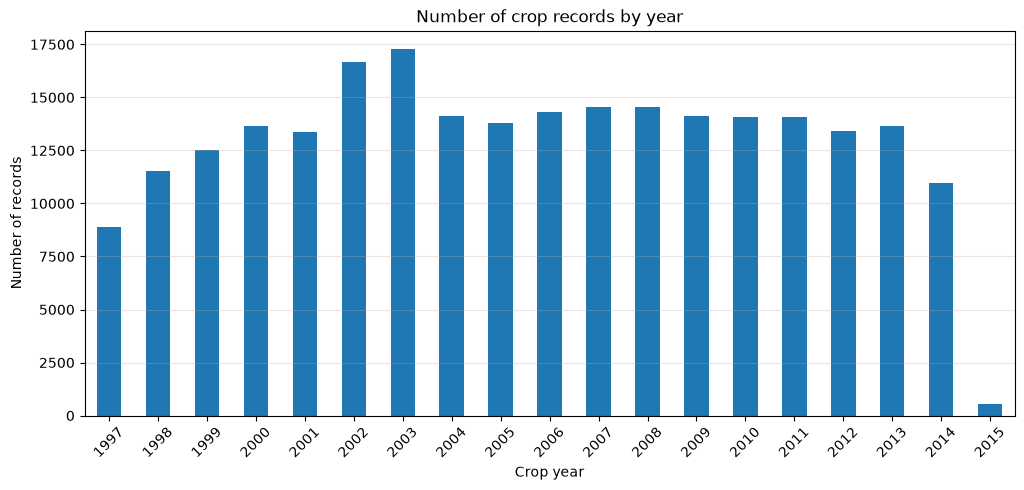

In [10]:
records_by_year = (
    df.groupby("Crop_Year")
      .size()
      .rename("record_count")
      .to_frame()
)

display(records_by_year)

ax = records_by_year.plot(
    kind="bar",
    figsize=(12, 5),
    legend=False,
    title="Number of crop records by year",
    xlabel="Crop year",
    ylabel="Number of records",
    rot=45,
)
ax.grid(axis="y", alpha=0.3)

### Investigate the latest year

A year with far fewer records than the others may be incomplete. We must check which states are present before deciding whether it can be included in India-wide comparisons.

In [11]:
latest_year = df["Crop_Year"].max()
latest_year_data = df.loc[df["Crop_Year"] == latest_year]

print(f"Latest year in dataset: {latest_year}")
print(f"Records in {latest_year}: {len(latest_year_data):,}")
print(
    f"States / Union Territories represented: "
    f"{latest_year_data['State_Name'].nunique()}"
)

print("\nRecords by state in the latest year:")
display(
    latest_year_data["State_Name"]
    .value_counts()
    .rename("record_count")
    .to_frame()
)

Latest year in dataset: 2015
Records in 2015: 562
States / Union Territories represented: 2

Records by state in the latest year:


,record_count
State_Name,
Odisha,527
Sikkim,35


## 11. Initial observations

After running the notebook, record the findings here. Do not assume missing values or unusual records should automatically be deleted; each issue needs a reasoned decision during the cleaning stage.

Consider documenting:
- Dataset dimensions and time coverage
- Geographic and crop coverage
- Missing-value locations
- Duplicate-record checks
- Text-formatting issues
- Whether the final year appears incomplete
- Any questions that need investigation before preprocessing

## Stage outcome

**No cleaning has been performed in this notebook.** The original CSV remains unchanged. The next notebook/stage will document and apply justified cleaning decisions.